# Монокулярная ORB VO (без замыкания петель)

**ORB-SLAM2**: предобработка → ORB-признаки → сопоставление → инициализация → триангуляция → PnP-трекинг → локальная карта.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'scripts' else Path.cwd()
print('Project root:', ROOT)

IMAGE_DIR   = ROOT / 'images'
TIMES_PATH  = ROOT / 'calib' / 'times.txt'
CALIB_PATH  = ROOT / 'calib' / 'camera_orb.yaml'

plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams["font.serif"] = ["Times New Roman"]

Project root: /home/sadovetsrv/dev_KAMAZ/big_dataset


### Предобработка

После устранения дисторсии создаём постоянную маску: нулевые области соответствуют перилам и другим элементам конструкции. Маска покрывает трубы с небольшим запасом, но сохраняет дорогу и борта карьера. Она передаётся в `detectAndCompute`

P.S.: При изменении положения камеры координаты маски нужно пересмотреть.

In [2]:
image_paths = sorted(IMAGE_DIR.glob('*.png'))
timestamps = np.loadtxt(TIMES_PATH)

print(f'Frames: {len(image_paths)}')
print(f'Duration: {timestamps[-1] - timestamps[0]:.3f} s')
print(f'Mean frame rate: {(len(timestamps) - 1) / (timestamps[-1] - timestamps[0]):.3f} Hz')

Frames: 599
Duration: 59.899 s
Mean frame rate: 9.983 Hz


In [3]:
# FileStorage открывает YAML калибровки в режиме чтения.
storage = cv2.FileStorage(str(CALIB_PATH), cv2.FILE_STORAGE_READ)

# getNode(...).real() читает скалярные параметры модели.
fx = storage.getNode('Camera.fx').real()
fy = storage.getNode('Camera.fy').real()
cx = storage.getNode('Camera.cx').real()
cy = storage.getNode('Camera.cy').real()

# Аналогично читаем пять коэффициентов дисторсии и закрываем YAML-файл.
distortion = np.array([storage.getNode(name).real() for name in
                       ['Camera.k1', 'Camera.k2', 'Camera.p1', 'Camera.p2', 'Camera.k3']])
storage.release()

if min(fx, fy) <= 0:
    raise ValueError('Заполните fx, fy, cx, cy и дисторсию в calib/camera_orb.yaml')

K = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=np.float64)

# imread загружает первый кадр в grayscale.
sample = cv2.imread(str(image_paths[0]), cv2.IMREAD_GRAYSCALE)
height, width = sample.shape

# initUndistortRectifyMap заранее вычисляет координаты источника для каждого выходного пикселя.
map_x, map_y = cv2.initUndistortRectifyMap(K, distortion, None, K, (width, height), cv2.CV_32FC1)

def load_gray(index):
    # Загружаем кадр по индексу в grayscale.
    gray = cv2.imread(str(image_paths[index]), cv2.IMREAD_GRAYSCALE)
    
    if gray is None:
        raise RuntimeError(f'Cannot read {image_paths[index]}')
    
    # remap применяет карты устранения дисторсии с билинейной интерполяцией яркости.
    return cv2.remap(gray, map_x, map_y, cv2.INTER_LINEAR)

print('K =\n', K)
print('Distortion =', distortion)

K =
 [[525.   0. 640.]
 [  0. 315. 360.]
 [  0.   0.   1.]]
Distortion = [0. 0. 0. 0. 0.]


Исключено маской: 252957 из 921600 пикселей (27.45%)
Осталось для ORB: 72.55% кадра


(np.float64(-0.5), np.float64(1279.5), np.float64(719.5), np.float64(-0.5))

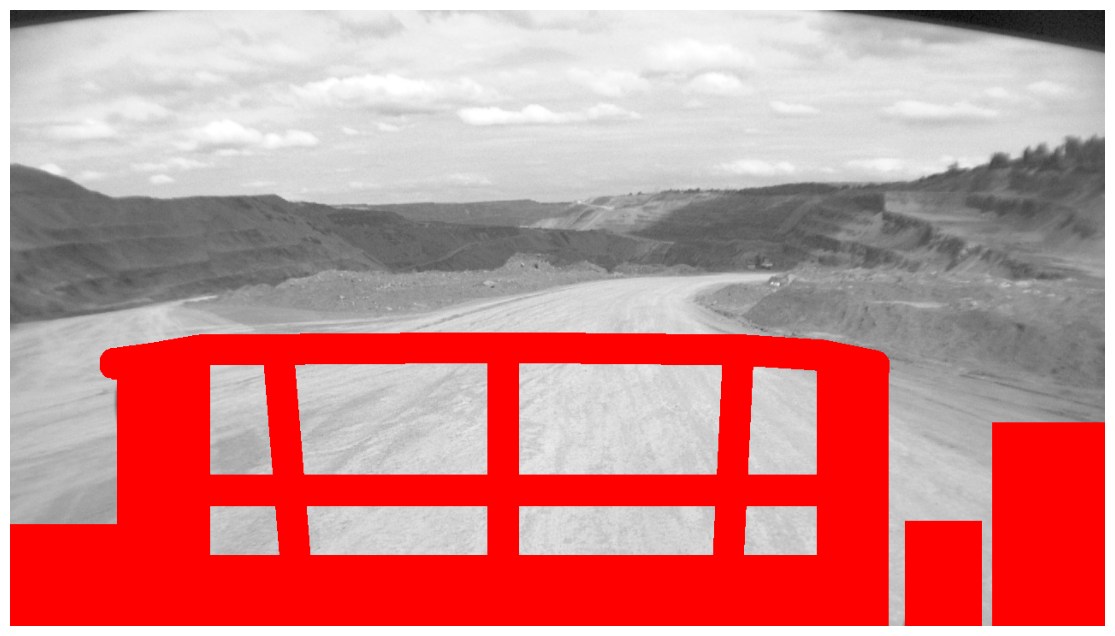

In [10]:
# Белый (255) — область поиска ORB, чёрный (0) — исключённая область.
feature_mask = np.full((height, width), 255, dtype=np.uint8)

# ЛИНИИ
# Точка (x, y) задаётся долями ширины и высоты: 
# (0, 0) — левый верхний угол, (1, 1) — правый нижний.
RAIL_POLYLINES = [
    # Верхняя горизонтальная труба и её изгибы.
    [(0.095, 0.575), (0.135, 0.565), (0.175, 0.552), (0.450, 0.548),
     (0.670, 0.552), (0.740, 0.560), (0.790, 0.578)],
    
    # Далее каждый список описывает отдельную стойку или фрагмент перил.
    [(0.245, 0.552), (0.265, 0.995)],
    [(0.450, 0.550), (0.450, 0.995)],
    [(0.665, 0.552), (0.655, 0.920)],
    [(0.175, 0.780), (0.735, 0.780)],
]

# ПРЯМОУГОЛЬНИКИ. Формат: (x_лево, y_верх, x_право, y_низ).
# Вся внутренняя область закрашивается нулём и исключается из детекции.
STATIC_RECTANGLES = [
    (0.000, 0.840, 0.100, 1.000),  # Перила в левой нижней части кадра.
    (0.100, 0.580, 0.180, 1.000),  # Перила слева "вверх".
    (0.120, 0.890, 0.800, 1.000),  # Нижняя площадка.
    (0.740, 0.580, 0.800, 1.000),  # Перила справа "вверх".
    (0.820, 0.835, 0.885, 1.000),  # Перила справа "между".
    (0.900, 0.675, 1.000, 1.000),  # Перила в правой нижней части кадра.
]

# Толщина линий и дополнительный запас вокруг ВСЕХ исключённых фигур, в пикселях.
# Если ORB всё ещё находит точки рядом с перилами, сначала увеличь MASK_MARGIN_PX.
RAIL_THICKNESS_PX = max(5, round(min(height, width) * 0.04))
MASK_MARGIN_PX = 3

def normalized_to_pixel(point):
    x, y = point
    return round(x * (width - 1)), round(y * (height - 1))

for polyline in RAIL_POLYLINES:
    points = np.array([normalized_to_pixel(point) for point in polyline], dtype=np.int32)
    
    # OpenCV рисует ломаную чёрным цветом (0), то есть помечает её как запрещённую.
    cv2.polylines(feature_mask, [points], False, 0, RAIL_THICKNESS_PX, cv2.LINE_AA)

for x1, y1, x2, y2 in STATIC_RECTANGLES:
    # thickness=-1 в cv2.rectangle означает закрашенный прямоугольник, а не только рамку.
    cv2.rectangle(feature_mask, normalized_to_pixel((x1, y1)),
                  normalized_to_pixel((x2, y2)), 0, thickness=-1)

# Расширяем чёрные области на MASK_MARGIN_PX во все стороны.
excluded_mask = 255 - feature_mask
if MASK_MARGIN_PX > 0:
    kernel_size = 2 * MASK_MARGIN_PX + 1
    
    # Морфологическая дилатация OpenCV расширяет ненулевые области excluded_mask.
    excluded_mask = cv2.dilate(excluded_mask, np.ones((kernel_size, kernel_size), np.uint8))
    
feature_mask = 255 - excluded_mask

# Считаем площадь именно итоговой маски: после объединения фигур и дилатации.
excluded_pixels = np.count_nonzero(feature_mask == 0)
excluded_percent = 100.0 * excluded_pixels / feature_mask.size
print(f'Исключено маской: {excluded_pixels} из {feature_mask.size} пикселей ({excluded_percent:.2f}%)')
print(f'Осталось для ORB: {100.0 - excluded_percent:.2f}% кадра')

# cvtColor преобразует grayscale в RGB, чтобы красным показать исключённые области.
mask_preview = cv2.cvtColor(load_gray(0), cv2.COLOR_GRAY2RGB)
mask_preview[feature_mask == 0] = (255, 0, 0)
plt.imshow(mask_preview)
plt.axis('off')

## 1. Feature Detection

ORB состоит из двух частей: **детектор** находит устойчивые ключевые точки, а **дескриптор** описывает изображение вокруг каждой точки. Детектор работает на пирамиде масштабов, поэтому одна и та же структура может находиться при разном размере в кадре.

- центр круга — координата ключевой точки;
- радиус круга — размер её характерной окрестности (`KeyPoint.size`), связанный с масштабом пирамиды; 
- радиус с радиальной линией — масштаб и главная ориентация точки; линия показывает направление, вычисленное по распределению яркости в окрестности.

Для каждой точки ORB вычисляет **256-битный бинарный дескриптор** (32 байта). Это результаты 256 попарных сравнений яркости в заданном шаблоне вокруг точки, повёрнутом на её главный угол. Два дескриптора сравниваются расстоянием Хэмминга — числом различающихся битов: 0 означает полное совпадение, а большее значение — менее похожие окрестности.

Detected keypoints: 864
Descriptor matrix: (864, 32) uint8


(np.float64(-0.5), np.float64(1279.5), np.float64(719.5), np.float64(-0.5))

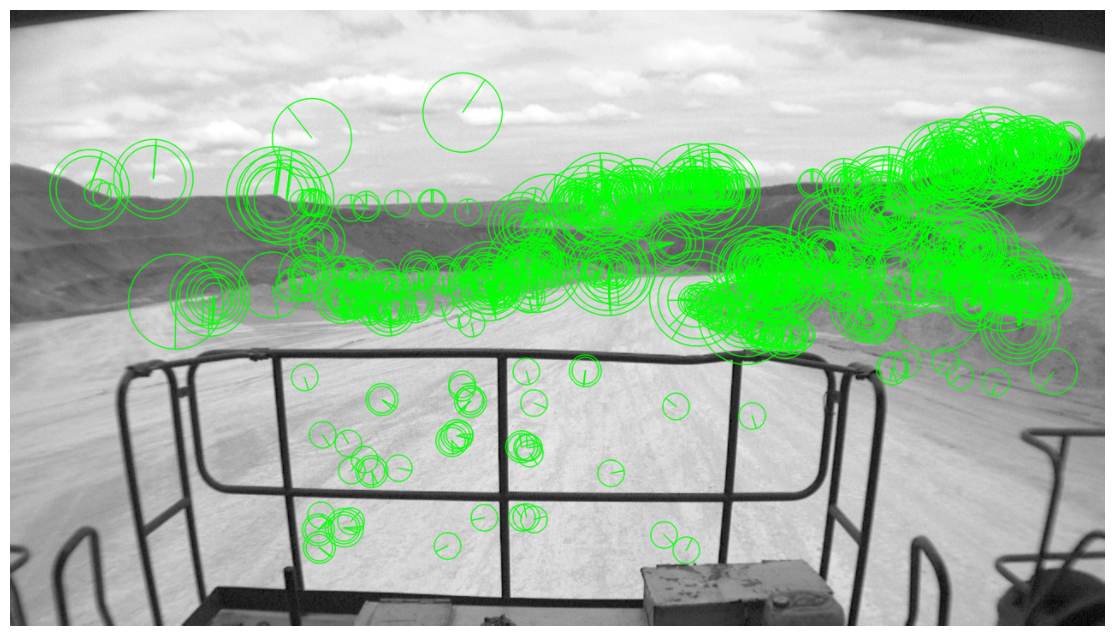

In [13]:
# ORB_create создаёт детектор+дескриптор: до 2000 точек, 8 уровней пирамиды,
# коэффициент уменьшения изображения 1.2 и порог FAST-детектора 20.
orb = cv2.ORB_create(nfeatures=2000, scaleFactor=1.2, nlevels=8, fastThreshold=20)

gray0 = load_gray(0)

# detectAndCompute возвращает ключевые точки и матрицу N×32 типа uint8:
# одна строка = один 256-битный дескриптор. feature_mask запрещает поиск в нулевых зонах.
keypoints0, descriptors0 = orb.detectAndCompute(gray0, feature_mask)
print('Detected keypoints:', len(keypoints0))
print('Descriptor matrix:', descriptors0.shape, descriptors0.dtype)

# drawKeypoints с DRAW_RICH_KEYPOINTS рисует масштаб кругом и ориентацию линией.
feature_image = cv2.drawKeypoints(gray0, keypoints0, None, color=(0, 255, 0),
                                  flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.imshow(feature_image)
plt.axis('off')

## 2. Feature Tracking

Feature Tracking - **сопоставление дескрипторов между двумя кадрами**.

1. `BFMatcher(NORM_HAMMING)` перебирает пары дескрипторов и сравнивает их по числу различающихся битов.
2. `knnMatch(..., k=2)` возвращает двух ближайших кандидатов для каждого дескриптора.
3. **Ratio test:** лучший кандидат принимается только при `best.distance < 0.75 × second_best.distance`. Если оба кандидата почти одинаково похожи, выбор неоднозначен и пара отбрасывается.
4. Поиск повторяется в обратную сторону. **Mutual check** оставляет пару A→B только если обратный поиск даёт B→A.
5. В `DMatch` поля `queryIdx` и `trainIdx` — индексы точек первого и второго кадра. По ним далее формируются пары пиксельных координат.

На рисунке соединяются центры сопоставленных точек; показаны максимум первые 100 пар. На этом этапе движение камеры ещё не оценивается: соответствия могут содержать ошибки, которые далее фильтрует RANSAC.

Keypoints: 864 → 964
Mutual ratio-test matches: 243
Matches / frame-0 keypoints: 28.1%


(np.float64(-0.5), np.float64(2559.5), np.float64(719.5), np.float64(-0.5))

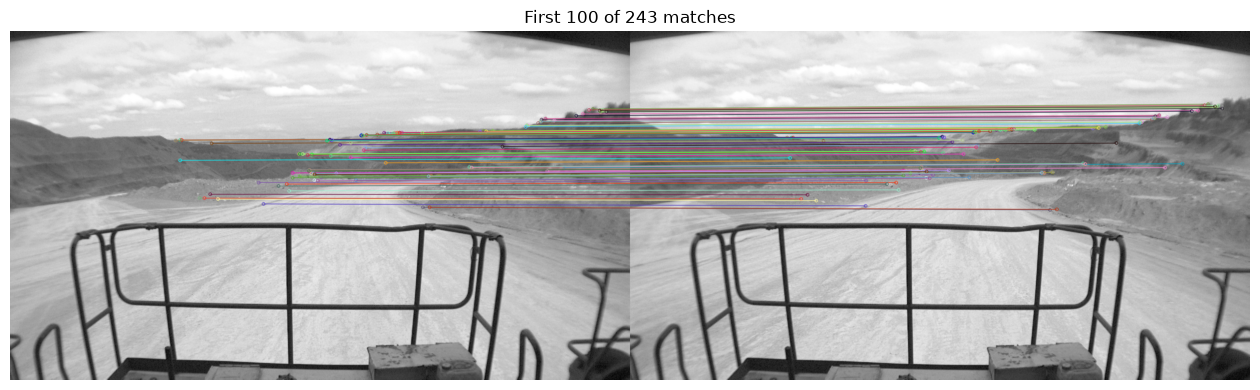

In [15]:
def match_descriptors(query, train, ratio=0.75):
    
    # BFMatcher выполняет полный перебор; NORM_HAMMING выбран для бинарных ORB-дескрипторов.
    matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
    # Для каждого дескриптора knnMatch возвращает два ближайших соседа (k=2).
    forward = matcher.knnMatch(query, train, k=2)
    backward = matcher.knnMatch(train, query, k=2)
    # Ratio test отбрасывает пары, у которых второй кандидат слишком похож на лучший.
    forward_good = [pair[0] for pair in forward if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance]
    backward_good = [pair[0] for pair in backward if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance]
    # Взаимная проверка: индексы должны образовывать пару в обоих направлениях.
    reverse = {match.queryIdx: match.trainIdx for match in backward_good}
    
    return [match for match in forward_good if reverse.get(match.trainIdx) == match.queryIdx]

INIT_FRAME_INDEX = 10
TRACK_FRAME_INDEX = INIT_FRAME_INDEX + 1
gray1 = load_gray(INIT_FRAME_INDEX)

# Повторяем детекцию ORB на новом кадре с той же маской предобработки.
keypoints1, descriptors1 = orb.detectAndCompute(gray1, feature_mask)
matches = match_descriptors(descriptors0, descriptors1)

print(f'Keypoints: {len(keypoints0)} → {len(keypoints1)}')
print(f'Mutual ratio-test matches: {len(matches)}')
print(f'Matches / frame-0 keypoints: {len(matches) / max(len(keypoints0), 1):.1%}')

# drawMatches соединяет сопоставленные точки; одиночные точки скрыты для читаемости.
match_image = cv2.drawMatches(gray0, keypoints0, gray1, keypoints1, matches[:100], None,
                              flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.imshow(match_image)
plt.title(f'First 100 of {len(matches)} matches')
plt.axis('off')

## 3. Motion Estimation

Из массива `matches` берём пары пиксельных координат `points0` и `points1`. По ним нужно найти относительное движение камеры, но часть соответствий всё ещё ошибочна.

**Essential matrix и RANSAC:**

1. Матрица `E` связывает лучи двух камер эпиполярным условием: соответствующая точка должна лежать около эпиполярной линии. Калибровка `K` переводит пиксели в нормированные координаты.
2. RANSAC многократно выбирает небольшую случайную группу соответствий, строит по ней кандидата `E` и проверяет остальные пары.
3. Пары с эпиполярной ошибкой не более `threshold=1.0` пикселя получают значение 1 в `essential_mask` — это **inliers**. Остальные — **outliers**. Ниже они показаны зелёным и красным соответственно.
`prob=0.999` задаёт желаемую вероятность найти согласованную модель; это не процент inliers.

**Восстановление позы:** `recoverPose` разлагает `E` на поворот `R` и направление перевода `t`, затем проверяет гипотезы через положительную глубину точек перед обеими камерами. `pose_mask` может содержать меньше точек, чем `essential_mask`, поскольку эпиполярный inlier не обязан иметь физически корректную глубину.

Длина `t` нормирована: монокулярная пара кадров даёт направление перевода, но не метры без внешнего масштаба. 

Essential inliers: 192/243 (79.0%)
Positive-depth pose inliers: 99
Rotation: 1.933 deg
Unit-scale translation direction: [-0.01665879  0.19044322 -0.98155686]


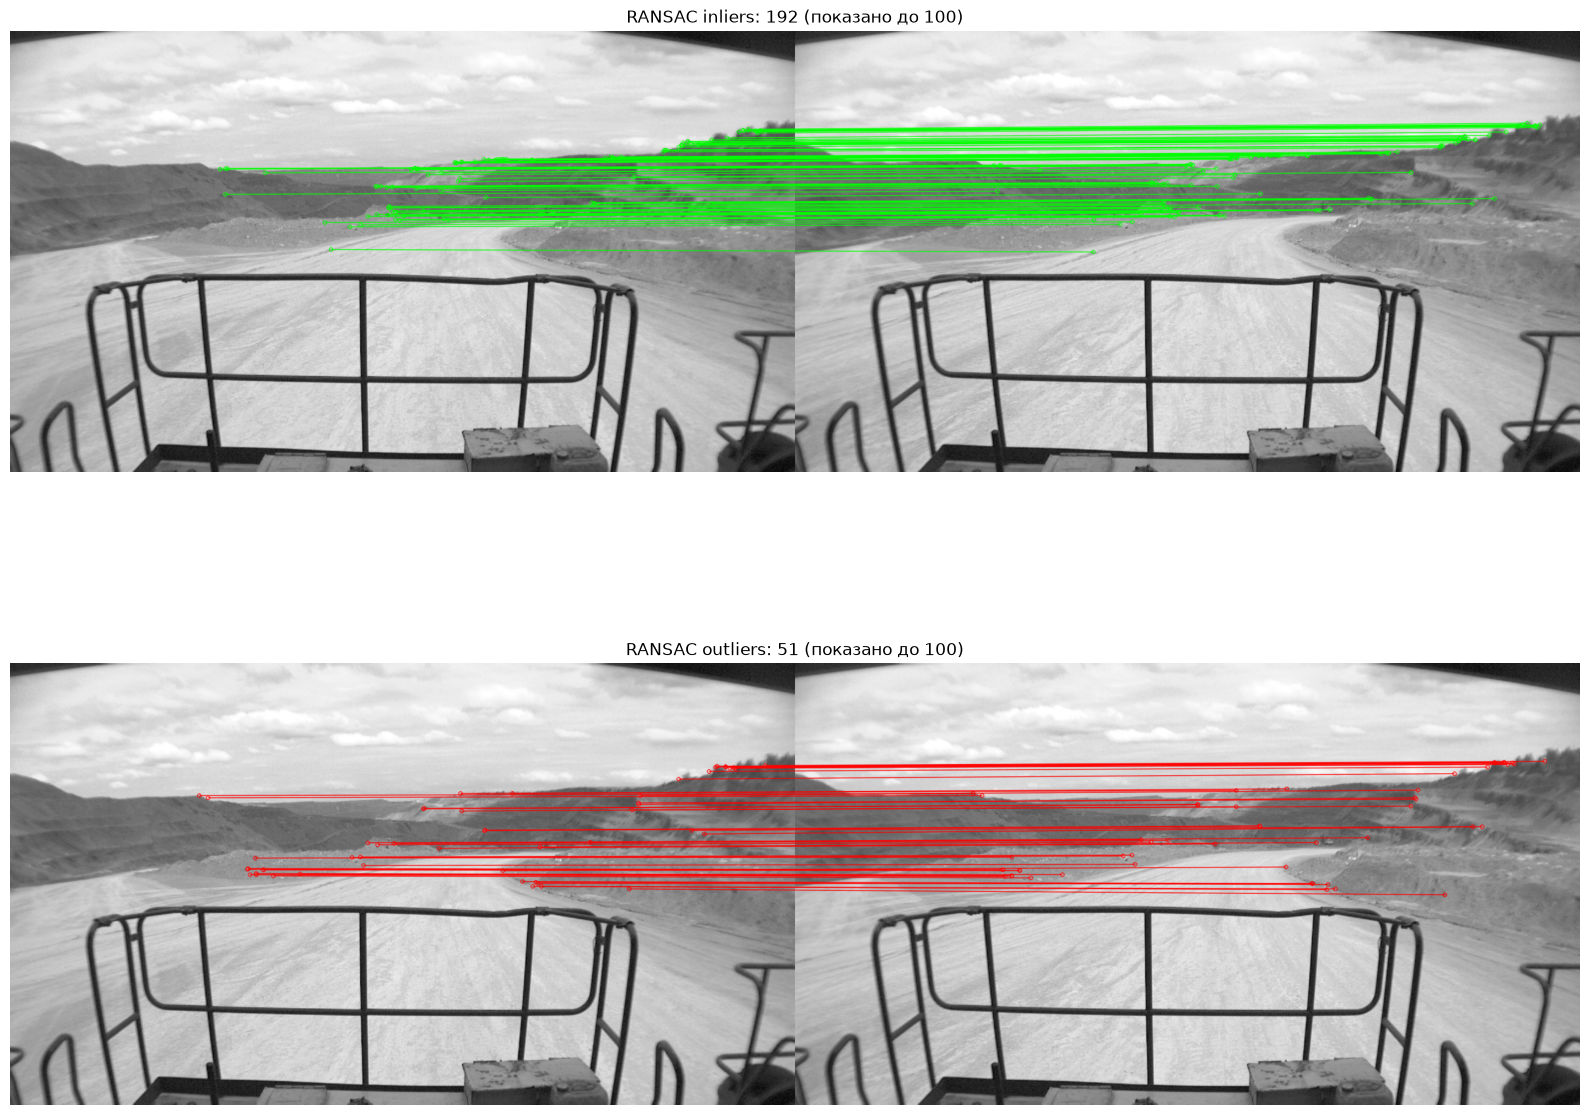

In [16]:
# Индексы DMatch превращаем в два массива пиксельных координат shape (N, 2).
points0 = np.float32([keypoints0[m.queryIdx].pt for m in matches])
points1 = np.float32([keypoints1[m.trainIdx].pt for m in matches])

# findEssentialMat оценивает E методом RANSAC; threshold — эпиполярный порог в пикселях.
# essential_mask — бинарный вектор: 1 для inliers, 0 для outliers.
E, essential_mask = cv2.findEssentialMat(points0, points1, K, method=cv2.RANSAC,
                                         prob=0.999, threshold=1.0)
if E is None or E.shape != (3, 3):
    raise RuntimeError('Essential matrix estimation failed')
# recoverPose получает R и единичный вектор t из E, проверяя положительную глубину точек.
_, R, t, pose_mask = cv2.recoverPose(E, points0, points1, K, mask=essential_mask.copy())

essential_inliers = int(essential_mask.sum())
pose_inliers = int(pose_mask.sum())

if pose_inliers < 20:
    raise RuntimeError('Мало точек с положительной глубиной: увеличьте INIT_FRAME_INDEX для большего параллакса')

# Угол поворота получаем из следа ортогональной матрицы R: trace(R)=1+2cos(theta).
rotation_deg = np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1)))
print(f'Essential inliers: {essential_inliers}/{len(matches)} ({essential_inliers / len(matches):.1%})')
print(f'Positive-depth pose inliers: {pose_inliers}')
print(f'Rotation: {rotation_deg:.3f} deg')
print('Unit-scale translation direction:', t.ravel())

# Разделяем исходные DMatch по маске RANSAC, сохраняя соответствие индексов.
is_ransac_inlier = essential_mask.ravel() > 0
inlier_matches = [match for match, keep in zip(matches, is_ransac_inlier) if keep]
outlier_matches = [match for match, keep in zip(matches, is_ransac_inlier) if not keep]

# drawMatches показывает зелёные inliers и красные outliers на отдельных панелях.
ransac_inlier_image = cv2.drawMatches(
    gray0, keypoints0, gray1, keypoints1, inlier_matches[:100], None,
    matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
ransac_outlier_image = cv2.drawMatches(
    gray0, keypoints0, gray1, keypoints1, outlier_matches[:100], None,
    matchColor=(255, 0, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

fig, axes = plt.subplots(2, 1, figsize=(16, 14))
axes[0].imshow(ransac_inlier_image)
axes[0].set_title(f'RANSAC inliers: {len(inlier_matches)} (показано до 100)')
axes[0].axis('off')
axes[1].imshow(ransac_outlier_image)
axes[1].set_title(f'RANSAC outliers: {len(outlier_matches)} (показано до 100)')
axes[1].axis('off')
plt.tight_layout()

## 4. Triangulation

Отбрасываем RANSAC-outliers, точки за камерами и точки с большой ошибкой репроекции. 
Численная устойчивость зависит от параллакса: при почти нулевом смещении глубина не определена.

In [ ]:
# P0 и P1 — матрицы проекции первой и второй камеры в одну систему координат.
P0 = K @ np.hstack((np.eye(3), np.zeros((3, 1))))
P1 = K @ np.hstack((R, t))
# triangulatePoints пересекает лучи соответствий и возвращает однородные 3D-точки 4×N.
homogeneous = cv2.triangulatePoints(P0, P1, points0.T, points1.T)
map_candidates = (homogeneous[:3] / homogeneous[3]).T

camera0 = map_candidates
camera1 = (R @ map_candidates.T + t).T
projected0 = (K @ camera0.T).T
projected1 = (K @ camera1.T).T
projected0 = projected0[:, :2] / projected0[:, 2:3]
projected1 = projected1[:, :2] / projected1[:, 2:3]
reprojection_error = 0.5 * (np.linalg.norm(projected0 - points0, axis=1) +
                            np.linalg.norm(projected1 - points1, axis=1))
valid = ((pose_mask.ravel() > 0) & (camera0[:, 2] > 0) & (camera1[:, 2] > 0) &
         np.isfinite(map_candidates).all(axis=1) & (reprojection_error < 2.0))

map_points = map_candidates[valid]
map_descriptors = descriptors1[[m.trainIdx for m, keep in zip(matches, valid) if keep]]
print(f'Valid map points: {len(map_points)}/{len(matches)}')

if len(map_points):
    print(f'Median triangulation reprojection error: {np.median(reprojection_error[valid]):.3f} px')

Valid map points: 99/243
Median triangulation reprojection error: 0.271 px


## 5. Map Tracking

После появления карты основной трекинг оценивает позу по соответствиям **3D map point → 2D keypoint**. `solvePnPRansac` устойчив к части ошибочных совпадений. Возвращаемые `R, t` преобразуют мировые точки в систему текущей камеры.

In [18]:
gray2 = load_gray(TRACK_FRAME_INDEX)
# Детектируем 2D-точки следующего кадра и сопоставляем их с дескрипторами 3D-карты.
keypoints2, descriptors2 = orb.detectAndCompute(gray2, feature_mask)
map_matches = match_descriptors(map_descriptors, descriptors2)
if len(map_matches) < 6:
    raise RuntimeError(f'Недостаточно 2D–3D соответствий: {len(map_matches)}')

object_points = np.float32([map_points[m.queryIdx] for m in map_matches])
image_points = np.float32([keypoints2[m.trainIdx].pt for m in map_matches])
# solvePnPRansac ищет позу по парам 3D→2D, отбрасывая ошибки репроекции более 2 px.
# rvec — вектор Родригеса, tvec — перевод мировой системы в систему камеры.

success, rvec, tvec, pnp_inliers = cv2.solvePnPRansac(
    object_points, image_points, K, None, iterationsCount=1000,
    reprojectionError=2.0, confidence=0.999, flags=cv2.SOLVEPNP_ITERATIVE)

if not success:
    raise RuntimeError('PnP failed')

# solvePnPRefineLM уточняет найденную позу методом Левенберга—Марквардта.
rvec, tvec = cv2.solvePnPRefineLM(object_points, image_points, K, None, rvec, tvec)
# Rodrigues преобразует компактный вектор вращения rvec в матрицу 3×3.
R_world_to_camera, _ = cv2.Rodrigues(rvec)
camera_center = -R_world_to_camera.T @ tvec

print(f'PnP inliers: {len(pnp_inliers)}/{len(map_matches)} ({len(pnp_inliers) / len(map_matches):.1%})')
print('Camera center in map coordinates:', camera_center.ravel())

PnP inliers: 73/78 (93.6%)
Camera center in map coordinates: [ 0.06079053 -0.24778774  1.06273543]
